# 🏦 Sberbank Analytical Assessment: SQL, Business Logic & Python
**Автор:** Иван Соловьев | **Дата:** Июль 2026

## 📋 Описание проекта
Комплексное тестовое задание для позиции аналитика в Сбербанк. Проект демонстрирует способность решать разнородные аналитические задачи: от написания оптимизированных SQL-запросов до построения управленческих дашбордов и анализа макроэкономических трендов.

### Структура задания:
1. **SQL Analytics:** Базовые запросы, агрегации, оконные функции и CTE.
2. **Business Visualization:** Трансляция абстрактного запроса руководителя в аналитический слайд (зарплатная сегментация).
3. **Market Analysis:** Гипотезы роста GMV маркетплейсов в марте 2022 года.
4. **Python ETL & Data Quality:** Обработка сырых логов, парсинг контрактов и контроль качества данных.

In [29]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Инициализация БД в памяти
conn = sqlite3.connect(':memory:')
cursor = conn.cursor()

# Создание таблиц
cursor.execute('''
CREATE TABLE clnt_aggr (
    client_dk INT, tb_name VARCHAR(100), salary FLOAT, 
    pos_amt FLOAT, pos_qty FLOAT
)
''')

cursor.execute('''
CREATE TABLE clnt_data (
    client_dk INT, gender VARCHAR(1), age INT, child_qty INT
)
''')

# Загрузка данных (из условия задания)
aggr_data = [
    (507851886, 'Московский банк', 15000, 6400, 8),
    (267188214, 'Центрально-Черноземный банк', 50000, 13200, 10),
    (148849526, 'Московский банк', 30000, 35000, 3),
    (613898474, 'Юго-Западный банк', 150000, 61000, 26),
    (774685437, 'Юго-Западный банк', 10000, 800, 2),
    (118943035, 'Московский банк', 70000, 44000, 19),
    (994153352, 'Центрально-Черноземный банк', 65000, 35000, 16)
]
cursor.executemany('INSERT INTO clnt_aggr VALUES (?,?,?,?,?)', aggr_data)

data_data = [
    (507851886, 'M', 25, 1), (267188214, 'M', 46, 3),
    (148849526, 'W', 18, 0), (613898474, 'M', 73, 2),
    (774685437, 'W', 24, 0), (118943035, 'W', 34, 2),
    (994153352, 'M', 35, 0)
]
cursor.executemany('INSERT INTO clnt_data VALUES (?,?,?,?)', data_data)
conn.commit()
print("✅ База данных успешно инициализирована.")

✅ База данных успешно инициализирована.


## Часть 1. Базовый SQL-анализ
Решение стандартных аналитических задач с использованием JOIN, GROUP BY и подзапросов.

In [30]:
### Задание 1: Количество клиентов по ТБ (pos_amt >= 1000)
query1 = '''SELECT 
    tb_name,
    COUNT(DISTINCT client_dk) AS client_count
FROM clnt_aggr 
WHERE pos_amt >= 1000
GROUP BY tb_name
ORDER BY client_count DESC;'''

df1 = pd.read_sql(query1, conn)
df1

,tb_name,client_count
0,Московский банк,3
1,Центрально-Черноземный банк,2
2,Юго-Западный банк,1


In [31]:
### Задание 2: Средняя зарплата и POS-оборот по возрасту
query2 = '''SELECT 
    cd.age,
    ROUND(AVG(ca.salary), 2) AS avg_salary,
    ROUND(AVG(ca.pos_amt), 2) AS avg_pos_amt
FROM clnt_aggr ca
JOIN clnt_data cd ON ca.client_dk = cd.client_dk
GROUP BY cd.age
ORDER BY cd.age;
'''

df2 = pd.read_sql(query2, conn)
df2

,age,avg_salary,avg_pos_amt
0,18,30000.0,35000.0
1,24,10000.0,800.0
2,25,15000.0,6400.0
3,34,70000.0,44000.0
4,35,65000.0,35000.0
5,46,50000.0,13200.0
6,73,150000.0,61000.0


### Задание 3: Распределение по банкам и возрастным группам
*Примечание:* Предоставлены два варианта вывода. Pivot-таблица удобна для руководителей, длинный формат — для загрузки в BI-системы. Границы возрастов интерпретированы как непересекающиеся интервалы.

In [32]:
### Вариант 1: Pivot-таблица (широкий формат)
query3_1 = '''SELECT 
    ca.tb_name,
    SUM(CASE WHEN cd.age < 18 THEN 1 ELSE 0 END) AS less_than_18,
    SUM(CASE WHEN cd.age >= 18 AND cd.age <= 30 THEN 1 ELSE 0 END) AS age_18_30,
    SUM(CASE WHEN cd.age > 30 AND cd.age <= 60 THEN 1 ELSE 0 END) AS age_30_60,
    SUM(CASE WHEN cd.age > 60 THEN 1 ELSE 0 END) AS over_60
FROM clnt_aggr ca
JOIN clnt_data cd ON ca.client_dk = cd.client_dk
GROUP BY ca.tb_name
ORDER BY ca.tb_name;
'''
df3_1 = pd.read_sql(query3_1, conn)
df3_1

,tb_name,less_than_18,age_18_30,age_30_60,over_60
0,Московский банк,0,2,1,0
1,Центрально-Черноземный банк,0,0,2,0
2,Юго-Западный банк,0,1,0,1


In [33]:
### Вариант 2: Длинный формат (нормализованный)
query3_2 = '''SELECT 
    ca.tb_name,
    CASE 
        WHEN cd.age < 18 THEN 'до 18'
        WHEN cd.age >= 18 AND cd.age <= 30 THEN '18-30'
        WHEN cd.age > 30 AND cd.age <= 60 THEN '30-60'
        ELSE 'более 60'
    END AS age_group,
    COUNT(DISTINCT ca.client_dk) AS client_count
FROM clnt_aggr ca
JOIN clnt_data cd ON ca.client_dk = cd.client_dk
GROUP BY ca.tb_name, age_group
ORDER BY ca.tb_name, age_group;'''

df3_2 = pd.read_sql(query3_2, conn)
df3_2

,tb_name,age_group,client_count
0,Московский банк,18-30,2
1,Московский банк,30-60,1
2,Центрально-Черноземный банк,30-60,2
3,Юго-Западный банк,18-30,1
4,Юго-Западный банк,более 60,1


In [34]:
### Задание 4: Клиенты с POS-оборотом выше среднего по базе
query4 = '''SELECT 
    client_dk
FROM clnt_aggr
WHERE pos_amt > (SELECT AVG(pos_amt) FROM clnt_aggr);'''

df4 = pd.read_sql(query4, conn)
df4

,client_dk
0,148849526
1,613898474
2,118943035
3,994153352


## Часть 2. Творческое задание: Аналитический слайд для руководства
**Запрос:** «Вывести распределение клиентов по уровню заработной платы».

**Подход:** Вместо сырой таблицы подготовлена визуализация, раскрывающая структуру портфеля и связь доходов с активностью использования карт.

In [35]:
### Шаг 1: Формирование сегментов и агрегация метрик
query5 = '''WITH salary_segments AS (
    SELECT 
        client_dk, tb_name, salary, pos_amt, pos_qty,
        CASE 
            WHEN salary < 30000 THEN 'Низкая (<30к)'
            WHEN salary >= 30000 AND salary < 70000 THEN 'Средняя (30-70к)'
            WHEN salary >= 70000 AND salary < 100000 THEN 'Выше среднего (70-100к)'
            ELSE 'Высокая (≥100к)'
        END AS salary_group
    FROM clnt_aggr
)
SELECT 
    salary_group,
    COUNT(DISTINCT client_dk) AS client_count,
    ROUND(COUNT(DISTINCT client_dk) * 100.0 / SUM(COUNT(DISTINCT client_dk)) OVER(), 2) AS share_pct,
    ROUND(AVG(salary), 2) AS avg_salary,
    ROUND(AVG(pos_amt), 2) AS avg_pos_amt,
    ROUND(AVG(pos_qty), 2) AS avg_pos_qty
FROM salary_segments
GROUP BY salary_group
ORDER BY avg_salary;'''

df5 = pd.read_sql(query5, conn)
df5

,salary_group,client_count,share_pct,avg_salary,avg_pos_amt,avg_pos_qty
0,Низкая (<30к),2,28.57,12500.00,3600.00,5.00
1,Средняя (30-70к),3,42.86,48333.33,27733.33,9.67
2,Выше среднего (70-100к),1,14.29,70000.00,44000.00,19.00
3,Высокая (≥100к),1,14.29,150000.00,61000.00,26.00


C:\Users\Ivan\AppData\Local\Temp\ipykernel_4028\829026795.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_viz, x='tb_name', y='salary', ax=axes[1], palette='muted')


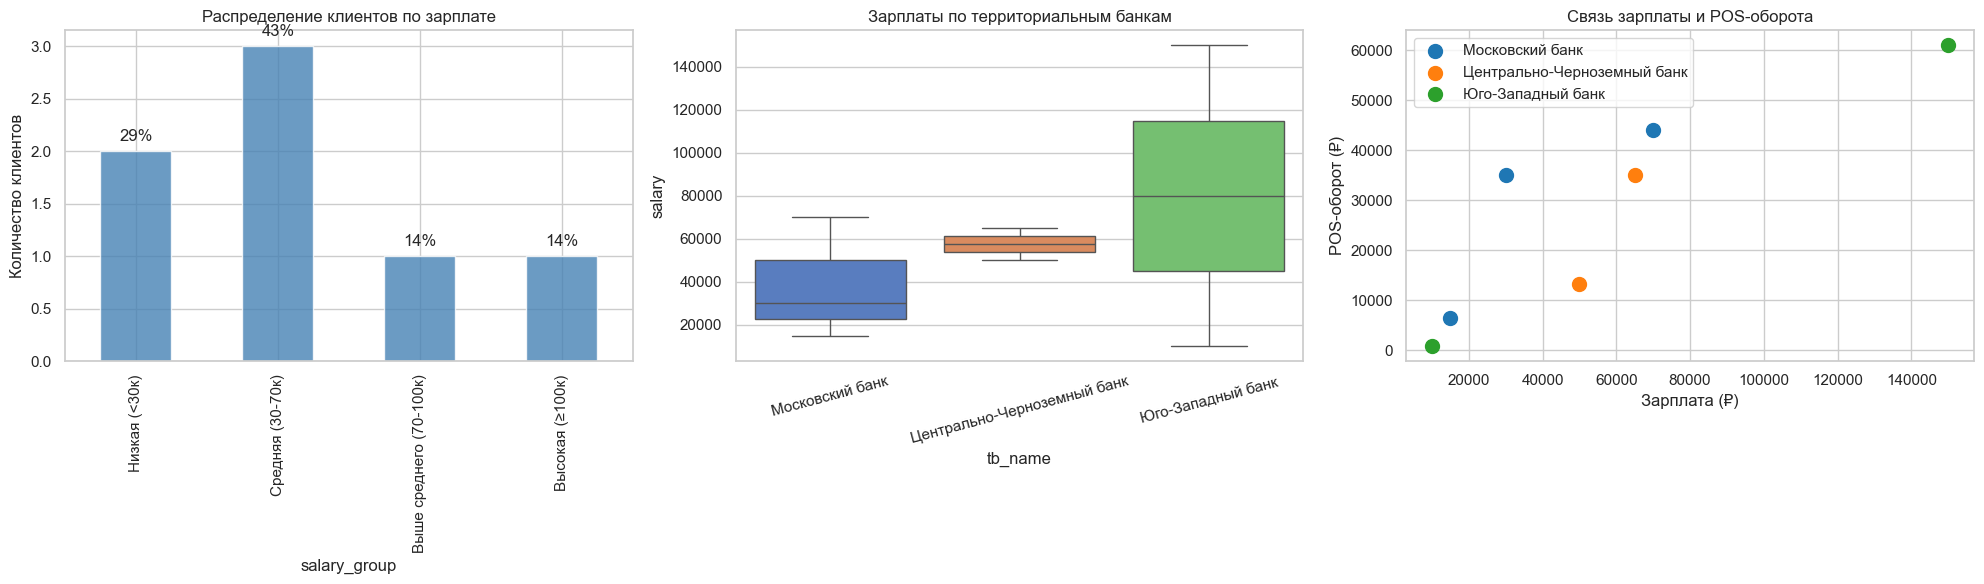

In [36]:
# Подготовка данных для визуализации
query_viz = """
SELECT client_dk, tb_name, salary, pos_amt,
CASE 
    WHEN salary < 30000 THEN 'Низкая (<30к)'
    WHEN salary >= 30000 AND salary < 70000 THEN 'Средняя (30-70к)'
    WHEN salary >= 70000 AND salary < 100000 THEN 'Выше среднего (70-100к)'
    ELSE 'Высокая (≥100к)'
END AS salary_group
FROM clnt_aggr"""

df_viz = pd.read_sql_query(query_viz, conn)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
sns.set_theme(style="whitegrid")

# График 1: Гистограмма распределения зарплат
counts = df_viz['salary_group'].value_counts().reindex(['Низкая (<30к)', 'Средняя (30-70к)', 'Выше среднего (70-100к)', 'Высокая (≥100к)'])
counts.plot(kind='bar', ax=axes[0], color='steelblue', alpha=0.8)
axes[0].set_title('Распределение клиентов по зарплате')
axes[0].set_ylabel('Количество клиентов')
for i, v in enumerate(counts):
    axes[0].text(i, v + 0.1, f"{v/len(df_viz)*100:.0f}%", ha='center')

# График 2: Box plot по территориальным банкам
sns.boxplot(data=df_viz, x='tb_name', y='salary', ax=axes[1], palette='muted')
axes[1].set_title('Зарплаты по территориальным банкам')
axes[1].tick_params(axis='x', rotation=15)

# График 3: Scatter plot (Зарплата vs POS-оборот)
colors = {'Московский банк': '#1f77b4', 'Центрально-Черноземный банк': '#ff7f0e', 'Юго-Западный банк': '#2ca02c'}
for bank, color in colors.items():
    subset = df_viz[df_viz['tb_name'] == bank]
    axes[2].scatter(subset['salary'], subset['pos_amt'], label=bank, color=color, marker='o', s=100)
axes[2].set_title('Связь зарплаты и POS-оборота')
axes[2].set_xlabel('Зарплата (₽)')
axes[2].set_ylabel('POS-оборот (₽)')
axes[2].legend()

plt.tight_layout()
plt.show()

### Выводы для слайда:
1. **Структура базы:** 72% клиентов имеют зарплату до 70к, формируя массовый сегмент.
2. **Региональные различия:** Юго-Западный банк имеет наибольший разброс зарплат (от 10к до 150к), требуя дифференцированной продуктовой стратегии.
3. **Корреляция активности:** Наблюдается прямая зависимость между зарплатой и POS-оборотом. Однако клиенты Московского банка с зарплатой ~30к показывают аномально высокий оборот (35к), что указывает на потенциал кредитных продуктов для этого сегмента.

## Часть 3. Бизнес-анализ: Гипотезы роста GMV маркетплейсов (Март 2022)
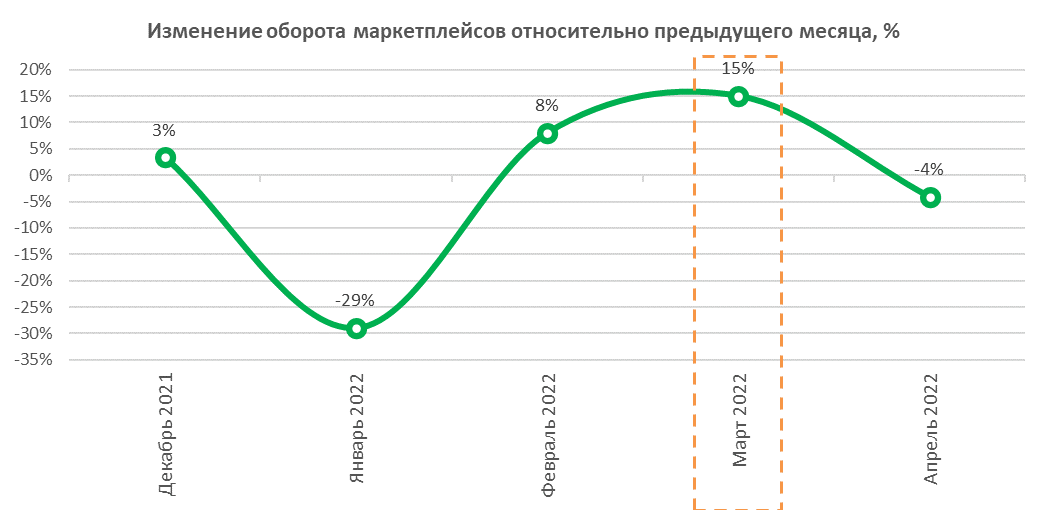

**Контекст:** Рост GMV на +15% м/м после падения в январе (-29%) и последующего спада в апреле (-4%).

### Ключевые гипотезы:
1. **Ажиотажный спрос (Основной драйвер, 60-70%):** Страх дефицита и девальвации рубля после 24.02.2022. Пик в категориях гигиены (+106%) и электроники. Перевод денег в товары как защита от инфляции.
2. **Эффект низкой базы (20-30%):** Статистический отскок от провального января (-29%).
3. **Перераспределение трафика (10-20%):** Уход международных ритейлеров (IKEA, H&M) перенаправил потребителей на маркетплейсы.
4. **Инфляционные ожидания:** Ослабление рубля (75₽ → 120₽/$) ускорило покупки импортных товаров "пока не подорожало".

### Почему рост сменился падением в апреле?
- Исчерпание ажиотажа и снижение реальных доходов.
- Дефицит товаров (особенно электроника -42,3%) из-за разрыва цепочек поставок.
- Логистические сложности с оплатой зарубежных товаров.

## Часть 4. Python: ETL, Парсинг и Data Quality
Задачи из дополнительных тестовых заданий: обработка сырых логов, извлечение идентификаторов контрактов и контроль качества данных.

Есть данные в файле **data_for_test.txt**. Необходимо написать код в питоне, который будет:

1.	Преобразовывать их к следующему виду:
	
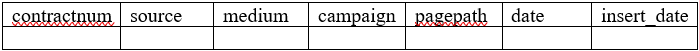			


- **contractnum** – номер заявки (набор цифр в поле eventLabel исходных данных после последнего подчеркивания)
- **insert_date** – дата обработки данных

2.	Сохранять в виде txt-файла с точкой с запятой в качестве разделителя

3.	**(Задание повышенной сложности).** Файлы с исходными данными хранятся в той же папке, что и файлы с обработанными данными, и загружаются каждый день с сохранением истории предыдущих файлов. Необходимо написать код, который будет самостоятельно определять последний файл с данными и брать его в обработку.


### Задания №1 и №2

In [37]:
import pandas as pd
from datetime import datetime

# Загрузка данных (предполагается наличие файла data_for_test.txt)
df = pd.read_csv('data_for_test.txt')

In [38]:
# 2. Извлекаем contractnum (цифры после последнего подчеркивания)
# Используем split('_') и берём последний элемент
df['contractnum'] = df['eventLabel'].str.split('_').str[-1]

# 3. Добавляем insert_date (текущая дата)
df['insert_date'] = datetime.now().strftime('%Y-%m-%d')

# 4. Переименовываем pagePath в pagepath
df = df.rename(columns={'pagePath': 'pagepath'})

# 5. Выбираем нужные колонки в правильном порядке
result = df[['contractnum', 'source', 'medium', 'campaign', 'pagepath', 'date', 'insert_date']]

In [39]:
# 6. Сохраняем в txt с разделителем ";"
result.to_csv('result.txt', sep=';', index=False)

print("Готово! Файл сохранён как result.txt")
print(f"Обработано строк: {len(result)}")

Готово! Файл сохранён как result.txt
Обработано строк: 20


### Задание повышенной сложности №3 

In [40]:
import os
import glob

# Находим все txt-файлы в папке
files = glob.glob('*.txt')

# Исключаем файл результата (если он уже есть)
files = [f for f in files if f != 'result.txt']

# Сортируем по дате модификации (последний = самый новый)
files.sort(key=os.path.getmtime, reverse=True)

# Берём первый (самый новый)
latest_file = files[0]
print(f"Обрабатываем файл: {latest_file}")

Обрабатываем файл: data_for_test.txt


In [41]:
# Далее код как заданиях 1 и 2
df = pd.read_csv(latest_file)
df['contractnum'] = df['eventLabel'].str.split('_').str[-1]
df['insert_date'] = datetime.now().strftime('%Y-%m-%d')
df = df.rename(columns={'pagePath': 'pagepath'})
result = df[['contractnum', 'source', 'medium', 'campaign', 'pagepath', 'date', 'insert_date']]
result.to_csv('result.txt', sep=';', index=False)

print(f"Готово! Обработано строк: {len(result)}")

Готово! Обработано строк: 20


## 💡 Заключение
Данный проект демонстрирует комплексный подход к аналитике:
- **Техническая глубина:** Уверенное владение SQL (CTE, Window Functions) и Python (Pandas, автоматизация ETL).
- **Бизнес-ориентированность:** Умение переводить абстрактные вопросы стейкхолдеров в конкретные визуализации и гипотезы.
- **Внимание к деталям:** Контроль качества данных, проверка граничных условий и учет контекста (геополитика, сезонность).

[GitHub Portfolio](https://github.com/azmat99094-glitch/My_projects.git) | [Telegram](https://t.me/Solova125rus)